In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
import sys


NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks" and (NOTEBOOK_DIR / "notebooks").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import importlib
import db_notebook_utils as dbu
importlib.reload(dbu)
from utils.movie_utils import read_astro_movie, spatial_bin_movie
from app.settings import load_settings
from app.db.core import connect
from db_notebook_utils import (
    available_experiments,
    load_confirmed_data,
    load_single_experiment_context,
    significant_cluster_counts,
    load_cluster_mask,
)


# Peaks Correlation Analysis From Confirmed Database

This notebook uses confirmed STA/cluster results from the app database. For population comparisons, it includes all Suite2p neurons from the selected experiment and loads their latest runtime spike labels so manual edits are respected.


In [6]:
# This notebook uses confirmed STA/cluster results from the app DB.
# For population comparisons, it loads all Suite2p cells and their latest runtime spike labels.
# "auto" picks the first available experiment with confirmed context rows; set to a canonical_id/experiment_id to choose one.
SINGLE_EXPERIMENT = "Hyp8__R__12-08-2026_ans__FOV1__z-120__x2"

experiments_df = available_experiments()
display(experiments_df)

single_choice = SINGLE_EXPERIMENT
if single_choice == "auto":
    available_single = experiments_df[experiments_df["n_confirmed_cells"].astype(int) > 0].copy()
    single_choice = None if available_single.empty else available_single.iloc[0]["canonical_id"]
if single_choice is None:
    raise ValueError("Set SINGLE_EXPERIMENT to one available canonical_id/experiment_id.")

# DB rows are used for confirmed STA/cluster results and to resolve source_path/fps/Suite2p paths.
single_data = load_confirmed_data(single_choice, latest_only=False)
ctx = load_single_experiment_context(single_data)

settings = load_settings()
with connect(settings) as conn:
    spike_run = conn.execute(
        """
        SELECT * FROM analysis_runs
        WHERE experiment_id=? AND step='spike' AND status='completed' AND is_test=0
        ORDER BY id DESC
        LIMIT 1
        """,
        (ctx.experiment_id,),
    ).fetchone()
if spike_run is None or not spike_run["output_dir"]:
    raise FileNotFoundError(f"No completed app spike run found for {ctx.canonical_id}. Run spike detection first.")
spike_output_dir = Path(spike_run["output_dir"])
if not spike_output_dir.exists():
    raise FileNotFoundError(f"Latest app spike output directory does not exist: {spike_output_dir}")

def _array_or_empty(value, dtype=np.int32):
    arr = np.asarray(value, dtype=dtype).ravel() if value is not None else np.asarray([], dtype=dtype)
    return arr[np.isfinite(arr)].astype(dtype) if np.issubdtype(arr.dtype, np.floating) else arr.astype(dtype)

def load_edited_spikes_for_cell(cell_id):
    path = spike_output_dir / f"cell_{int(cell_id)}" / "simple_complex_spike_labels.npz"
    if not path.exists():
        return np.asarray([], dtype=np.int32), np.asarray([], dtype=np.int32), np.asarray([], dtype=np.int32), "missing_runtime_spike_file"
    with np.load(path, allow_pickle=True) as d:
        peaks = np.asarray(d["peaks_all"], dtype=np.int32) if "peaks_all" in d else np.asarray([], dtype=np.int32)
        labels = np.asarray(d["labels"]).astype(str) if "labels" in d else np.full(peaks.shape, "simple")
    order = np.argsort(peaks)
    peaks = peaks[order]
    labels = np.char.lower(labels[order].astype("U16"))
    keep = labels != "exclude"
    all_peaks = peaks[keep]
    simple_peaks = peaks[labels == "simple"]
    complex_peaks = peaks[labels == "complex"]
    source = "edited_runtime" if (path.parent / "manual_spike_review.json").exists() else "runtime_spike_run"
    return np.sort(all_peaks), np.sort(simple_peaks), np.sort(complex_peaks), source

peak_rows = []
for cell_id in range(int(ctx.suite2p_ctx["n_cells"])):
    all_peaks, simple_peaks, complex_peaks, peak_source = load_edited_spikes_for_cell(cell_id)
    peak_rows.append({
        "experiment_id": ctx.experiment_id,
        "canonical_id": ctx.canonical_id,
        "cell_id": int(cell_id),
        "all_peaks": all_peaks,
        "simple_peaks": simple_peaks,
        "complex_peaks": complex_peaks,
        "n_all_peaks": int(all_peaks.size),
        "n_simple_peaks": int(simple_peaks.size),
        "n_complex_peaks": int(complex_peaks.size),
        "peak_source": peak_source,
    })
peaks_df = pd.DataFrame(peak_rows).sort_values("cell_id").reset_index(drop=True)

clusters_df = single_data.clusters.copy()
if clusters_df.empty:
    clusters_df = pd.DataFrame(columns=[
        "experiment_id", "canonical_id", "cell_id", "cluster_id", "result_type", "sign",
        "is_significant", "mask_artifact_path", "spatial_bin",
    ])
else:
    clusters_df["cell_id"] = clusters_df["cell_id"].astype(int)
    clusters_df["cluster_id"] = clusters_df["cluster_id"].astype(int)
    clusters_df["is_significant"] = clusters_df["is_significant"].astype(bool)
    if "sign" in clusters_df:
        clusters_df["sign"] = clusters_df["sign"].astype(str).str.lower()

data = single_data  # Kept for helper compatibility; analysis tables above are DB clusters plus runtime all-neuron peaks.
print(
    f"Loaded DB confirmed STA clusters and runtime spike peaks for {ctx.canonical_id}: "
    f"{len(peaks_df)} Suite2p neurons, {len(clusters_df)} DB cluster rows "
    f"({int(clusters_df['is_significant'].sum()) if not clusters_df.empty else 0} significant), "
    f"spike run {int(spike_run['id'])}."
)
display(peaks_df["peak_source"].value_counts().rename_axis("peak_source").reset_index(name="n_cells"))

def center_zero_ylim(ax, pad=0.08):
    ymin, ymax = ax.get_ylim()
    finite = [abs(v) for v in (ymin, ymax) if np.isfinite(v)]
    radius = max(finite) if finite else 1.0
    if radius == 0:
        radius = 1.0
    radius *= 1 + float(pad)
    ax.set_ylim(-radius, radius)

def cluster_mask_from_row(row):
    if "mask2d" in row and row["mask2d"] is not None:
        return np.asarray(row["mask2d"], dtype=bool)
    return load_cluster_mask(row)


,experiment_id,canonical_id,source_path,recording_date,n_confirmed_cells
0,1,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,02-02-2026,23
1,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,40
2,8,Hyp8__R__12-08-2026_ans__FOV2__z-43__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,2
3,9,Hyp8__X__12-08-2026_ans__FOV1__z-116__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,19
4,5,Hyp7__X__15-06-2026_ans__FOV1__z-96__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,15-06-2026,19
5,2,Hyp6__R__25-05-2026_awake__FOV2__z-30__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,25-05-2026,16
6,4,Hyp6__R__27-04-2026_awake__FOV1__z-110__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,27-04-2026,42
7,3,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,30-12-2025,5


Loaded DB confirmed STA clusters and runtime spike peaks for Hyp8__R__12-08-2026_ans__FOV1__z-120__x2: 272 Suite2p neurons, 4429 DB cluster rows (97 significant), spike run 45.


,peak_source,n_cells
0,edited_runtime,269
1,runtime_spike_run,3


In [7]:
def spike_counts_for_group(peaks_df, bin_seconds=1.0):
    rows = []
    matrices = {}
    for (experiment_id, canonical_id), exp_peaks in peaks_df.groupby(["experiment_id", "canonical_id"], sort=False):
        all_peak_arrays = [np.asarray(v, dtype=np.int32) for v in exp_peaks["all_peaks"]]
        max_peak = max((int(p.max()) for p in all_peak_arrays if p.size), default=0)
        fps = 1.0
        # Correlations only need a stable bin width in frames; use 1 second when single-experiment fps is loaded elsewhere.
        bin_frames = max(1, int(round(bin_seconds * fps)))
        n_bins = max(1, int(np.ceil((max_peak + 1) / bin_frames)))
        cell_ids = exp_peaks["cell_id"].to_numpy(dtype=int)
        counts = np.zeros((len(cell_ids), n_bins), dtype=np.float32)
        for row_idx, peaks in enumerate(all_peak_arrays):
            bins = np.floor_divide(peaks, bin_frames)
            bins = bins[(bins >= 0) & (bins < n_bins)]
            if bins.size:
                counts[row_idx] = np.bincount(bins, minlength=n_bins).astype(np.float32)
        matrices[int(experiment_id)] = {"canonical_id": canonical_id, "cell_ids": cell_ids, "counts": counts}
    return matrices


def pairwise_spike_correlations(peaks_df, clusters_df, bin_frames=30):
    sig_counts = significant_cluster_counts(clusters_df)
    pair_rows = []
    for (experiment_id, canonical_id), exp_peaks in peaks_df.groupby(["experiment_id", "canonical_id"], sort=False):
        peak_arrays = {int(r.cell_id): np.asarray(r.all_peaks, dtype=np.int32) for r in exp_peaks.itertuples()}
        max_peak = max((int(p.max()) for p in peak_arrays.values() if p.size), default=0)
        n_bins = max(1, int(np.ceil((max_peak + 1) / max(1, bin_frames))))
        cell_ids = np.asarray(sorted(peak_arrays), dtype=int)
        counts = np.zeros((cell_ids.size, n_bins), dtype=np.float32)
        for i, cell_id in enumerate(cell_ids):
            bins = np.floor_divide(peak_arrays[int(cell_id)], bin_frames)
            bins = bins[(bins >= 0) & (bins < n_bins)]
            if bins.size:
                counts[i] = np.bincount(bins, minlength=n_bins).astype(np.float32)
        keep = counts.std(axis=1) > 0
        cell_ids = cell_ids[keep]
        counts = counts[keep]
        if counts.shape[0] < 2:
            continue
        corr = np.corrcoef(counts)
        for i, cell_i in enumerate(cell_ids):
            for j in range(i + 1, cell_ids.size):
                cell_j = int(cell_ids[j])
                pair_rows.append({
                    "experiment_id": int(experiment_id),
                    "canonical_id": canonical_id,
                    "cell_i": int(cell_i),
                    "cell_j": cell_j,
                    "correlation": float(corr[i, j]),
                    "n_spikes_i": int(peak_arrays[int(cell_i)].size),
                    "n_spikes_j": int(peak_arrays[cell_j].size),
                    "n_sig_clusters_i": int(sig_counts.get((int(experiment_id), int(cell_i)), 0)),
                    "n_sig_clusters_j": int(sig_counts.get((int(experiment_id), cell_j), 0)),
                })
    return pd.DataFrame(pair_rows)

# peaks_df and clusters_df were built in the setup cell from runtime all-neuron spikes and DB-confirmed STA clusters.
pairwise_df = pairwise_spike_correlations(peaks_df, clusters_df, bin_frames=30)
if pairwise_df.empty:
    raise ValueError("No pairwise correlations could be computed from the selected confirmed rows.")

def peak_overlap_fraction(a, b, tolerance_frames=5):
    a = np.asarray(a, dtype=np.int32)
    b = np.asarray(b, dtype=np.int32)
    if a.size == 0 or b.size == 0:
        return 0.0
    pos = np.searchsorted(b, a)
    overlap = np.zeros(a.size, dtype=bool)
    valid = pos < b.size
    overlap[valid] |= np.abs(b[pos[valid]] - a[valid]) <= tolerance_frames
    valid_prev = pos > 0
    overlap[valid_prev] |= np.abs(b[pos[valid_prev] - 1] - a[valid_prev]) <= tolerance_frames
    return float(overlap.sum() / max(1, min(a.size, b.size)))

peak_lookup = {(int(r.experiment_id), int(r.cell_id)): np.asarray(r.all_peaks, dtype=np.int32) for r in peaks_df.itertuples()}
sig_cluster_sets = {
    (int(exp_id), int(cell_id)): set(g["cluster_id"].astype(int))
    for (exp_id, cell_id), g in clusters_df[clusters_df["is_significant"]].groupby(["experiment_id", "cell_id"])
}
for idx, row in pairwise_df.iterrows():
    key_i = (int(row.experiment_id), int(row.cell_i))
    key_j = (int(row.experiment_id), int(row.cell_j))
    clusters_i = sig_cluster_sets.get(key_i, set())
    clusters_j = sig_cluster_sets.get(key_j, set())
    shared = clusters_i & clusters_j
    union = clusters_i | clusters_j
    pairwise_df.loc[idx, "peak_overlap_fraction"] = peak_overlap_fraction(peak_lookup[key_i], peak_lookup[key_j])
    pairwise_df.loc[idx, "cluster_overlap_fraction"] = len(shared) / max(1, min(len(clusters_i), len(clusters_j)))
    pairwise_df.loc[idx, "cluster_jaccard"] = len(shared) / len(union) if union else np.nan

display(pairwise_df.head(20))


,experiment_id,canonical_id,cell_i,cell_j,correlation,n_spikes_i,n_spikes_j,n_sig_clusters_i,n_sig_clusters_j,peak_overlap_fraction,cluster_overlap_fraction,cluster_jaccard
0,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,1,0.096210,9,23,0,1,0.111111,0.0,0.0
1,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,2,-0.035898,9,12,0,0,0.000000,0.0,NaN
2,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,3,-0.047001,9,20,0,0,0.000000,0.0,NaN
3,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,4,-0.041742,9,16,0,1,0.000000,0.0,0.0
4,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,5,-0.025123,9,6,0,0,0.000000,0.0,NaN
5,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,6,0.049311,9,15,0,3,0.111111,0.0,0.0
6,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,7,-0.040346,9,15,0,0,0.000000,0.0,NaN
7,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,8,0.002532,9,32,0,0,0.000000,0.0,NaN
8,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,9,-0.054173,9,26,0,0,0.000000,0.0,NaN
9,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,0,10,-0.032657,9,10,0,0,0.000000,0.0,NaN


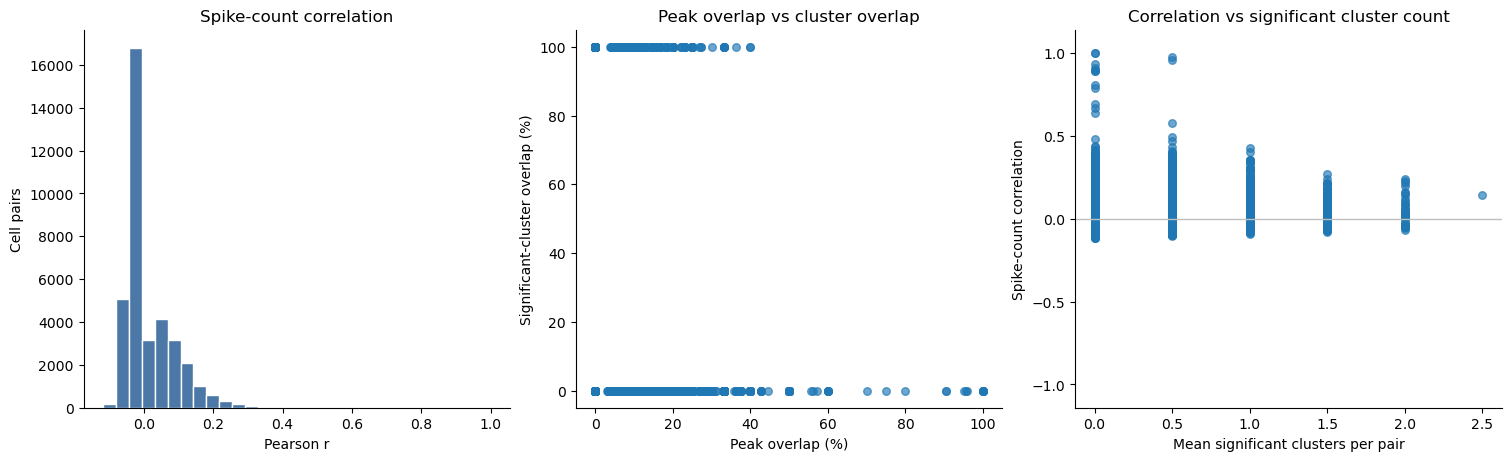

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axes[0].hist(pairwise_df["correlation"], bins=30, color="#4C78A8", edgecolor="white")
axes[0].set_title("Spike-count correlation")
axes[0].set_xlabel("Pearson r")
axes[0].set_ylabel("Cell pairs")

axes[1].scatter(100 * pairwise_df["peak_overlap_fraction"], 100 * pairwise_df["cluster_overlap_fraction"], alpha=0.65, s=30)
axes[1].set_title("Peak overlap vs cluster overlap")
axes[1].set_xlabel("Peak overlap (%)")
axes[1].set_ylabel("Significant-cluster overlap (%)")

axes[2].scatter(pairwise_df[["n_sig_clusters_i", "n_sig_clusters_j"]].mean(axis=1), pairwise_df["correlation"], alpha=0.65, s=30)
axes[2].axhline(0, color="0.75", linewidth=1)
center_zero_ylim(axes[2])
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
axes[2].set_title("Correlation vs significant cluster count")
axes[2].set_xlabel("Mean significant clusters per pair")
axes[2].set_ylabel("Spike-count correlation")
plt.show()


## Restored Original-Style Peak Analyses

These sections use DB-confirmed STA clusters together with all-neuron runtime spike labels from the selected experiment.


In [9]:
# Shared helpers for restored original-style analyses.
sig_counts_all = significant_cluster_counts(clusters_df)
sig_cluster_sets = {
    (int(exp_id), int(cell_id)): set(g["cluster_id"].astype(int))
    for (exp_id, cell_id), g in clusters_df[clusters_df["is_significant"]].groupby(["experiment_id", "cell_id"])
}
peak_lookup = {
    (int(r.experiment_id), int(r.cell_id)): np.asarray(r.all_peaks, dtype=np.int32)
    for r in peaks_df.itertuples()
}

def experiment_spike_matrix(exp_peaks, bin_frames=30):
    peak_arrays = {int(r.cell_id): np.asarray(r.all_peaks, dtype=np.int32) for r in exp_peaks.itertuples()}
    cell_ids = np.asarray(sorted(peak_arrays), dtype=int)
    max_peak = max((int(p.max()) for p in peak_arrays.values() if p.size), default=0)
    n_bins = max(1, int(np.ceil((max_peak + 1) / max(1, int(bin_frames)))))
    counts = np.zeros((cell_ids.size, n_bins), dtype=np.float32)
    for i, cell_id in enumerate(cell_ids):
        bins = np.floor_divide(peak_arrays[int(cell_id)], int(bin_frames))
        bins = bins[(bins >= 0) & (bins < n_bins)]
        if bins.size:
            counts[i] = np.bincount(bins, minlength=n_bins).astype(np.float32)
    return cell_ids, peak_arrays, counts

def sorted_cells_by_sig_then_peaks(exp_peaks):
    rows = []
    for r in exp_peaks.itertuples():
        key = (int(r.experiment_id), int(r.cell_id))
        rows.append((int(r.cell_id), int(sig_counts_all.get(key, 0)), int(r.n_all_peaks)))
    rows = sorted(rows, key=lambda x: (-x[1], -x[2], x[0]))
    return np.asarray([r[0] for r in rows], dtype=int), np.asarray([r[1] for r in rows], dtype=int)

def plot_raster(ax, ordered_cells, peak_arrays, title, x_scale=1.0, x_label="Frame"):
    max_x = 1.0
    for y, cell_id in enumerate(ordered_cells):
        peaks = np.asarray(peak_arrays.get(int(cell_id), []), dtype=np.int32)
        if peaks.size:
            ax.vlines(peaks / x_scale, y - 0.4, y + 0.4, color="black", linewidth=0.3)
            max_x = max(max_x, float(peaks.max() / x_scale))
    if len(ordered_cells):
        ax.set_ylim(len(ordered_cells) - 0.5, -0.5)
    else:
        ax.set_ylim(0.5, -0.5)
        ax.text(0.5, 0.5, "No cells", transform=ax.transAxes, ha="center", va="center", color="0.45")
    ax.set_xlim(0, max_x)
    ax.set_yticks([])
    ax.set_ylabel("Cell")
    ax.set_xlabel(x_label)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)


## Rasters Sorted by Significant Clusters and Peak Count


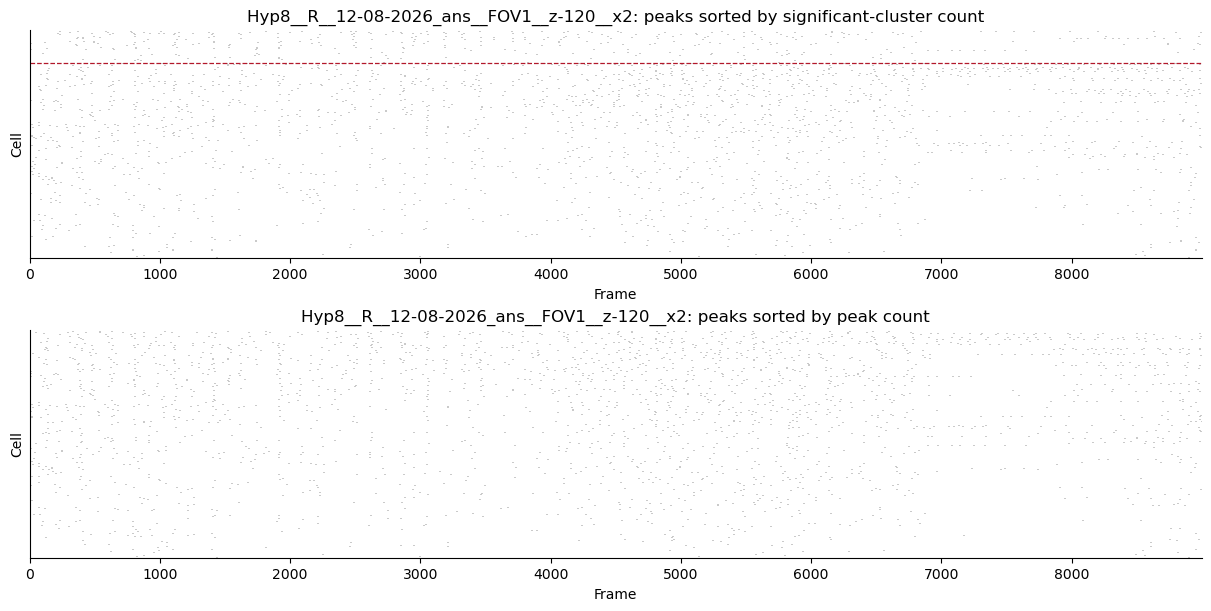

In [10]:
for (experiment_id, canonical_id), exp_peaks in peaks_df.groupby(["experiment_id", "canonical_id"], sort=False):
    ordered_sig, n_sig_sorted = sorted_cells_by_sig_then_peaks(exp_peaks)
    peak_arrays = {int(r.cell_id): np.asarray(r.all_peaks, dtype=np.int32) for r in exp_peaks.itertuples()}
    ordered_peaks = exp_peaks.sort_values(["n_all_peaks", "cell_id"], ascending=[False, True])["cell_id"].to_numpy(dtype=int)
    first_non_sig = np.flatnonzero(n_sig_sorted == 0)

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
    plot_raster(axes[0], ordered_sig, peak_arrays, f"{canonical_id}: peaks sorted by significant-cluster count")
    if first_non_sig.size:
        axes[0].axhline(first_non_sig[0] - 0.5, color="#b2182b", linestyle="--", linewidth=0.9)
    plot_raster(axes[1], ordered_peaks, peak_arrays, f"{canonical_id}: peaks sorted by peak count")
    plt.show()


## Split Rasters and Population Histograms


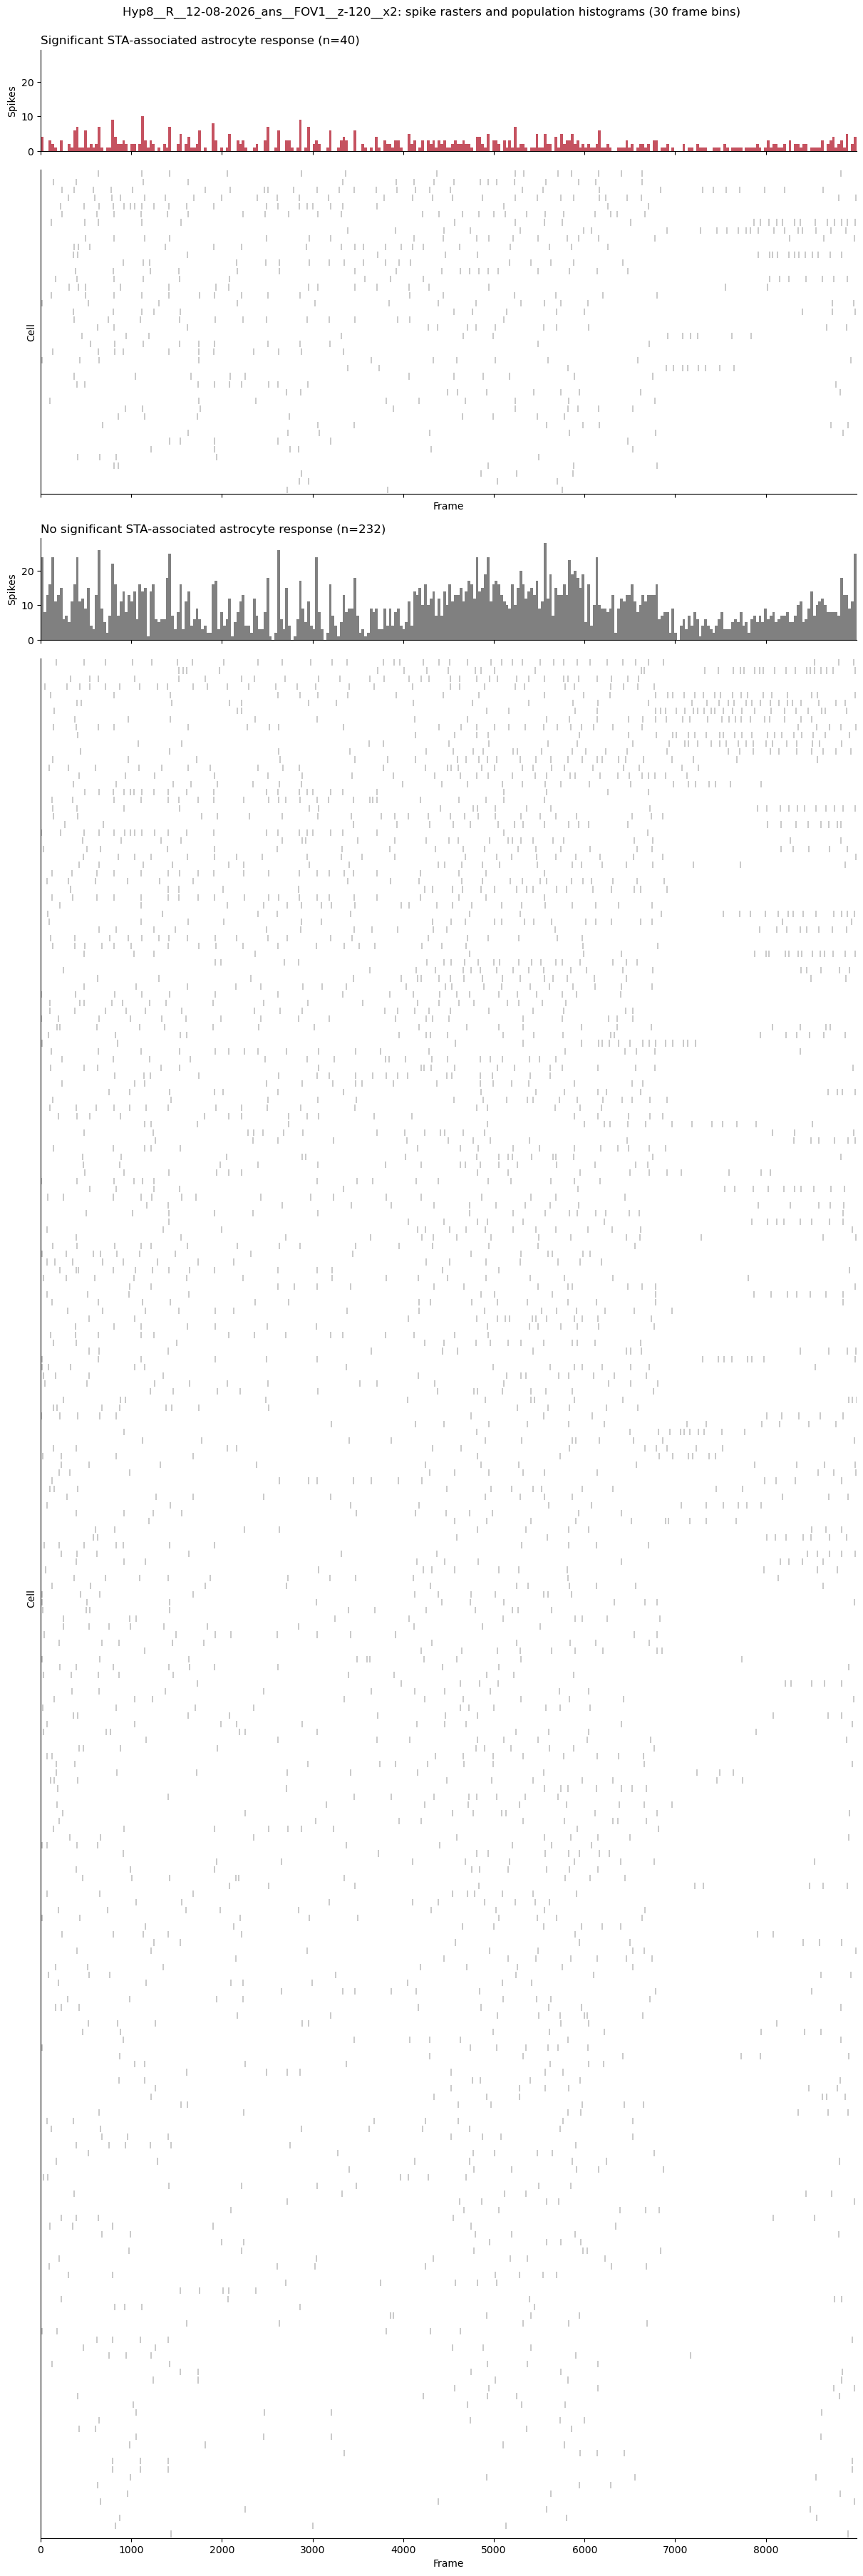

In [11]:
hist_bin_frames = 30
for (experiment_id, canonical_id), exp_peaks in peaks_df.groupby(["experiment_id", "canonical_id"], sort=False):
    ordered_cells, n_sig_sorted = sorted_cells_by_sig_then_peaks(exp_peaks)
    peak_arrays = {int(r.cell_id): np.asarray(r.all_peaks, dtype=np.int32) for r in exp_peaks.itertuples()}
    sig_cells = ordered_cells[n_sig_sorted > 0]
    no_sig_cells = ordered_cells[n_sig_sorted == 0]
    max_peak = max((int(p.max()) for p in peak_arrays.values() if p.size), default=0)
    edges = np.arange(0, max_peak + hist_bin_frames + 1, hist_bin_frames)

    def group_counts(cells):
        arrays = [peak_arrays[int(c)] for c in cells if peak_arrays[int(c)].size]
        if not arrays:
            return np.zeros(edges.size - 1, dtype=int)
        return np.histogram(np.concatenate(arrays), bins=edges)[0]

    groups = [
        (sig_cells, group_counts(sig_cells), "#b2182b", "Significant STA-associated astrocyte response"),
        (no_sig_cells, group_counts(no_sig_cells), "#555555", "No significant STA-associated astrocyte response"),
    ]
    ymax = max(1, *(int(g[1].max(initial=0)) for g in groups))
    fig, axes = plt.subplots(4, 1, figsize=(12, max(5, 0.12 * len(ordered_cells) + 3)), sharex=True, gridspec_kw={"height_ratios": [1, max(1, len(sig_cells) * 0.08), 1, max(1, len(no_sig_cells) * 0.08)]}, constrained_layout=True)
    for row, (cells_, counts, color, title) in enumerate(groups):
        hist_ax, raster_ax = axes[2 * row], axes[2 * row + 1]
        hist_ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=color, alpha=0.75, linewidth=0)
        hist_ax.set_ylabel("Spikes")
        hist_ax.set_ylim(0, ymax * 1.05)
        hist_ax.set_title(f"{title} (n={len(cells_)})", loc="left")
        plot_raster(raster_ax, cells_, peak_arrays, "", x_label="Frame")
        for ax in (hist_ax, raster_ax):
            ax.spines[["top", "right"]].set_visible(False)
    axes[-1].set_xlabel("Frame")
    fig.suptitle(f"{canonical_id}: spike rasters and population histograms ({hist_bin_frames} frame bins)", y=1.01)
    plt.show()


## Correlation by Significant-Cluster Status


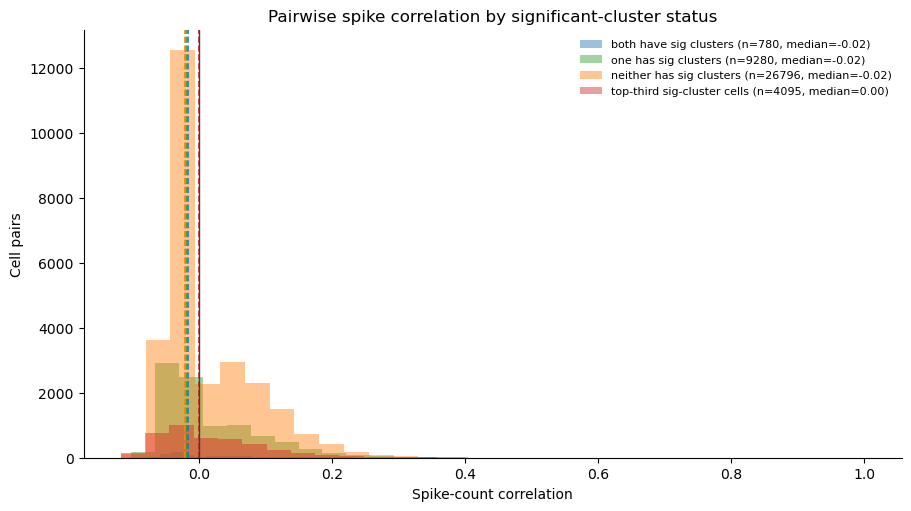

In [12]:
pair_groups = {
    "both have sig clusters": pairwise_df[(pairwise_df["n_sig_clusters_i"] > 0) & (pairwise_df["n_sig_clusters_j"] > 0)]["correlation"],
    "one has sig clusters": pairwise_df[((pairwise_df["n_sig_clusters_i"] > 0) ^ (pairwise_df["n_sig_clusters_j"] > 0))]["correlation"],
    "neither has sig clusters": pairwise_df[(pairwise_df["n_sig_clusters_i"] == 0) & (pairwise_df["n_sig_clusters_j"] == 0)]["correlation"],
}
# Top-third significant-cluster cells are computed within each experiment, then pooled by pair.
top_keys = set()
for experiment_id, exp_peaks in peaks_df.groupby("experiment_id"):
    counts = exp_peaks["cell_id"].map(lambda c: int(sig_counts_all.get((int(experiment_id), int(c)), 0)))
    ranked = exp_peaks.assign(n_sig=counts).sort_values(["n_sig", "n_all_peaks"], ascending=[False, False])
    keep = ranked.head(max(1, int(np.ceil(len(ranked) / 3))))
    top_keys.update((int(experiment_id), int(c)) for c in keep["cell_id"])
top_mask = pairwise_df.apply(lambda r: (int(r.experiment_id), int(r.cell_i)) in top_keys and (int(r.experiment_id), int(r.cell_j)) in top_keys, axis=1)
pair_groups["top-third sig-cluster cells"] = pairwise_df.loc[top_mask, "correlation"]

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]
for (label, values), color in zip(pair_groups.items(), colors):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    if not values.size:
        continue
    ax.hist(values, bins=30, alpha=0.45, label=f"{label} (n={values.size}, median={np.nanmedian(values):.2f})", color=color)
    ax.axvline(np.nanmedian(values), color=color, linestyle="--", linewidth=1.2)
ax.axvline(0, color="0.25", linewidth=1)
ax.set_title("Pairwise spike correlation by significant-cluster status")
ax.set_xlabel("Spike-count correlation")
ax.set_ylabel("Cell pairs")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


## Sorted Spike-Correlation Heatmaps


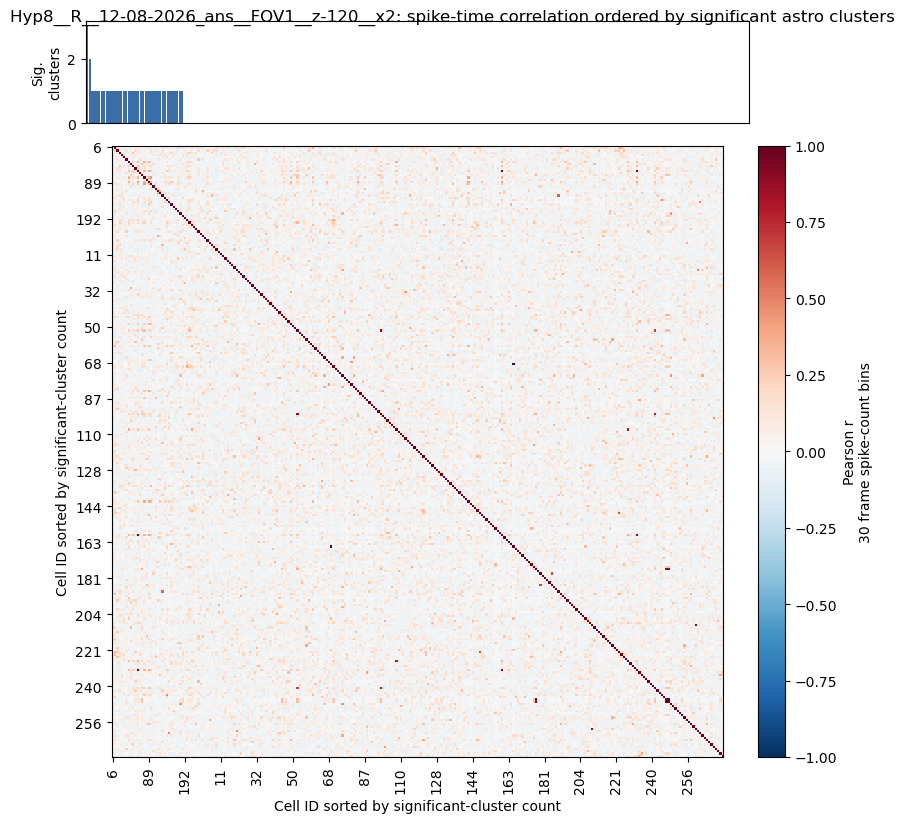

In [13]:
for (experiment_id, canonical_id), exp_peaks in peaks_df.groupby(["experiment_id", "canonical_id"], sort=False):
    cell_ids, peak_arrays, counts = experiment_spike_matrix(exp_peaks, bin_frames=30)
    keep = counts.std(axis=1) > 0
    cell_ids = cell_ids[keep]
    counts = counts[keep]
    if cell_ids.size < 2:
        print(f"{canonical_id}: skipped heatmap, fewer than two variable cells.")
        continue
    corr = np.corrcoef(counts)
    n_sig = np.asarray([int(sig_counts_all.get((int(experiment_id), int(c)), 0)) for c in cell_ids])
    order = np.lexsort((cell_ids, -n_sig))
    fig = plt.figure(figsize=(8.5, 8), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 6], width_ratios=[6, 0.25])
    ax_bar = fig.add_subplot(gs[0, 0])
    ax_heat = fig.add_subplot(gs[1, 0])
    cax = fig.add_subplot(gs[1, 1])
    rank = np.arange(cell_ids.size)
    ax_bar.bar(rank, n_sig[order], color="#3B6EA8", width=0.9)
    ax_bar.set_ylabel("Sig.\nclusters")
    ax_bar.set_xticks([])
    ax_bar.set_xlim(-0.5, cell_ids.size - 0.5)
    im = ax_heat.imshow(corr[order][:, order], vmin=-1, vmax=1, cmap="RdBu_r", interpolation="nearest", aspect="equal")
    step = max(1, int(np.ceil(cell_ids.size / 18)))
    locs = np.arange(0, cell_ids.size, step)
    labels = cell_ids[order][locs]
    ax_heat.set_xticks(locs); ax_heat.set_xticklabels(labels, rotation=90)
    ax_heat.set_yticks(locs); ax_heat.set_yticklabels(labels)
    ax_heat.set_xlabel("Cell ID sorted by significant-cluster count")
    ax_heat.set_ylabel("Cell ID sorted by significant-cluster count")
    fig.colorbar(im, cax=cax, label="Pearson r\n30 frame spike-count bins")
    fig.suptitle(f"{canonical_id}: spike-time correlation ordered by significant astro clusters", y=1.01)
    plt.show()


## Top Significant-Cluster Cells: Traces and ROI Overlay


DB/runtime sections loaded Hyp8__R__12-08-2026_ans__FOV1__z-120__x2; selected 55 top significant-cluster cells from 272 neurons.


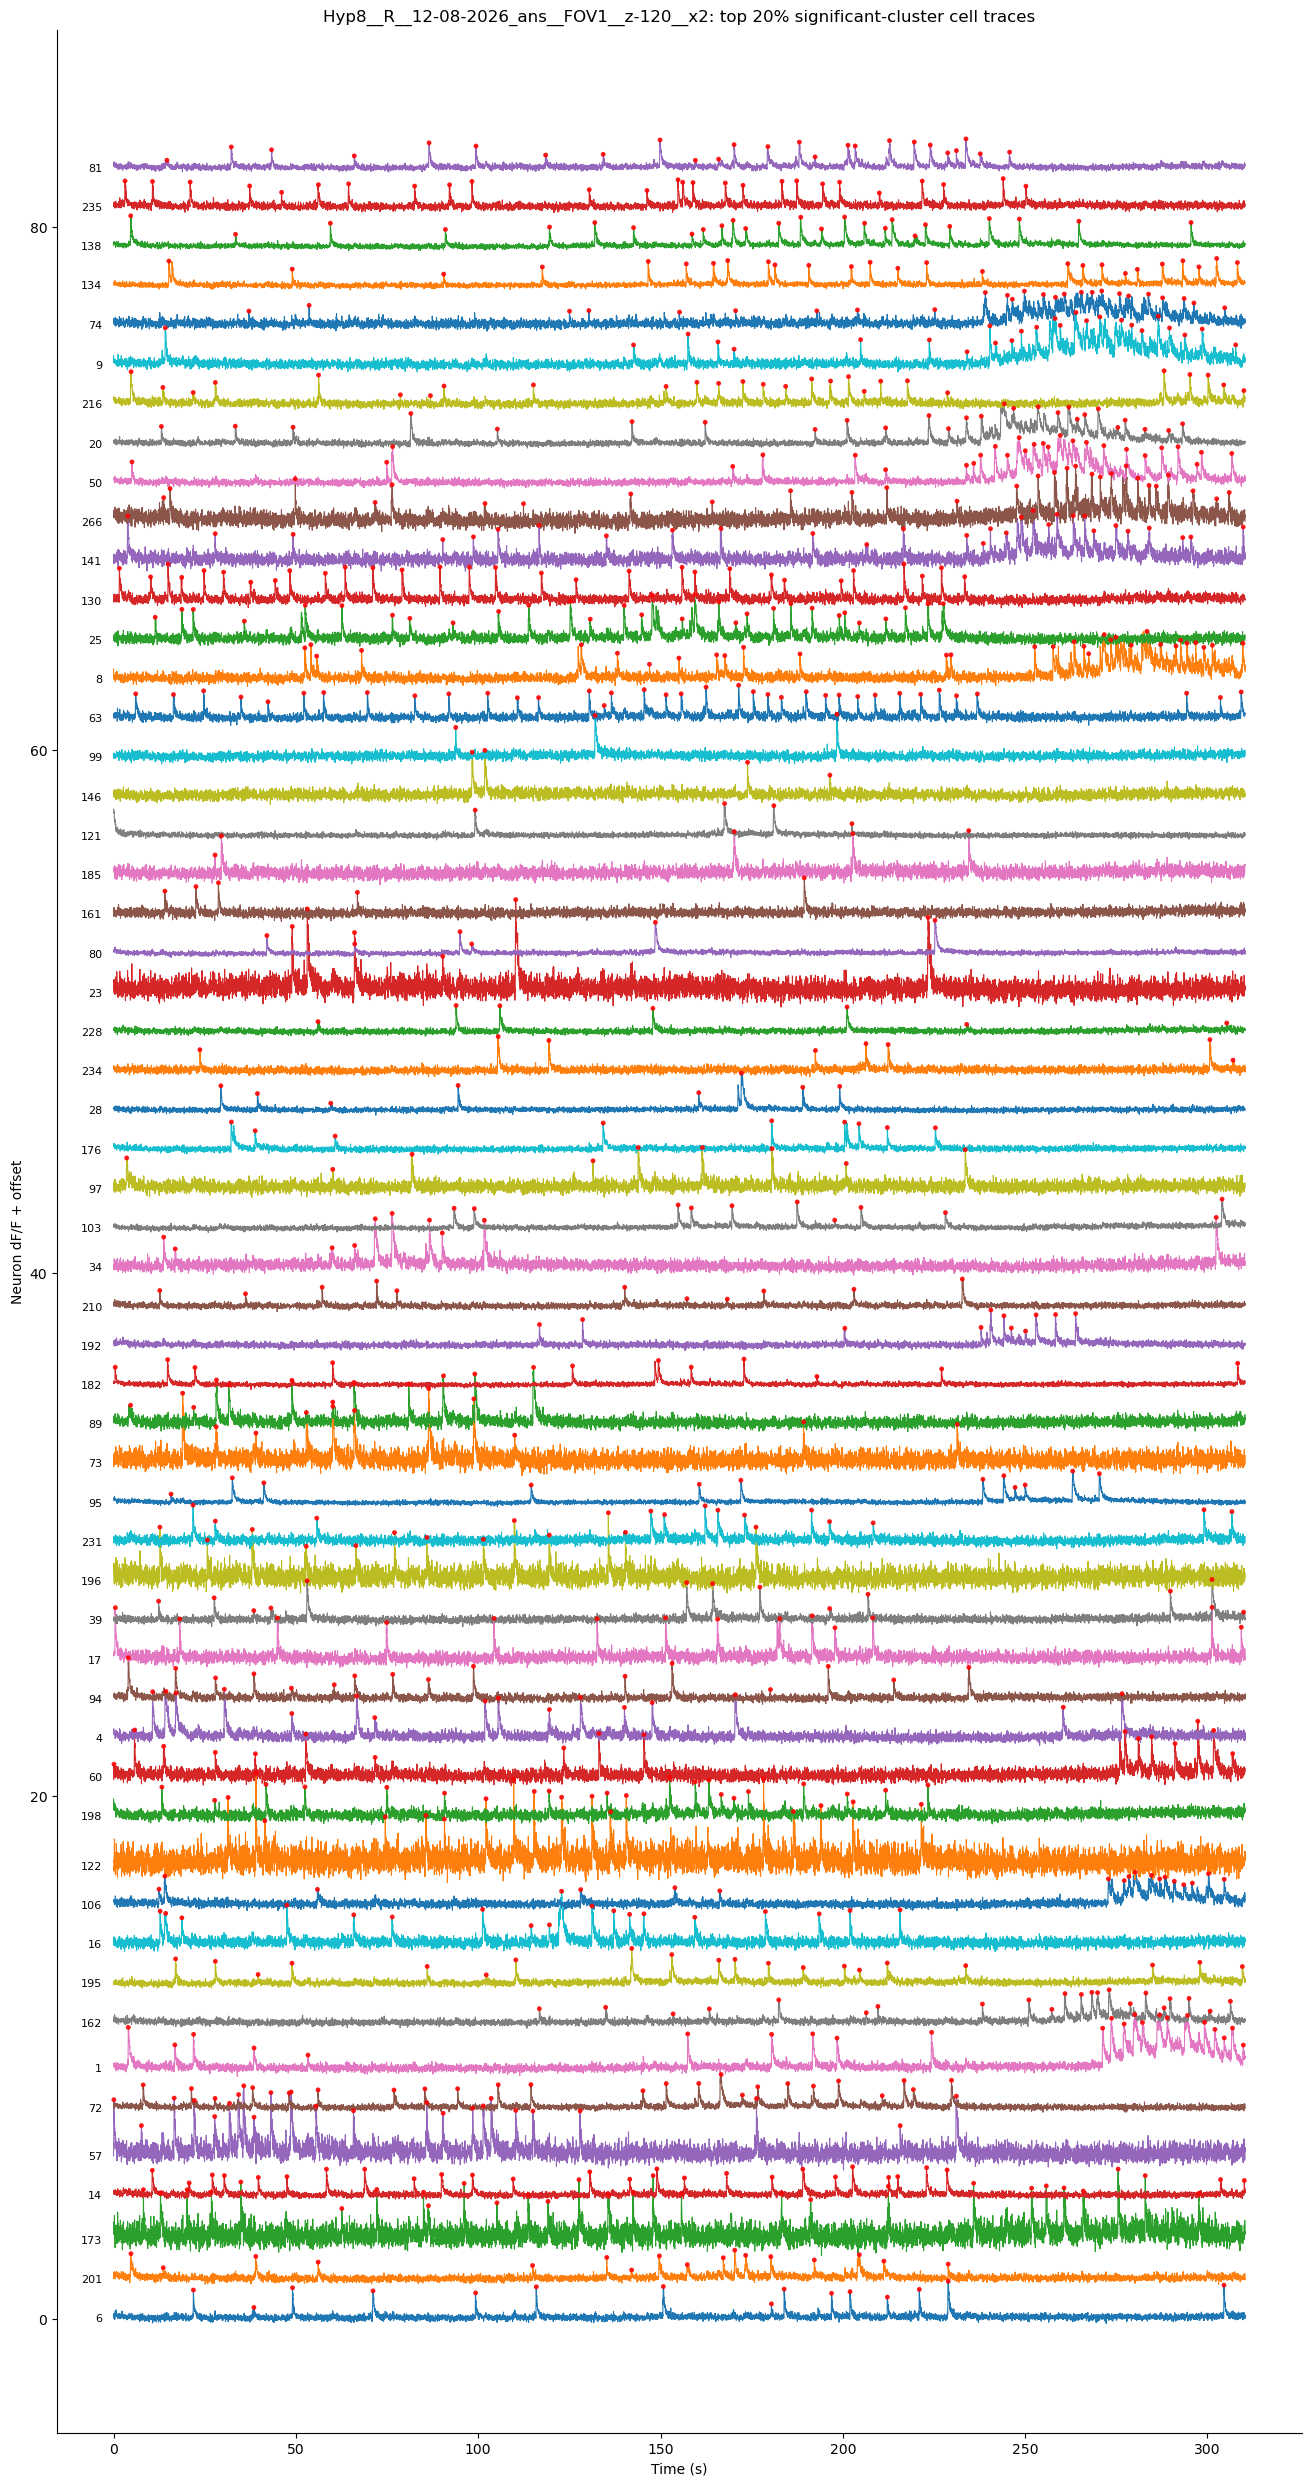

In [14]:
single_experiment_ready = True
exp_peaks = peaks_df.copy()
exp_clusters = clusters_df.copy()
exp_sig_clusters = exp_clusters[exp_clusters["is_significant"]].copy()
exp_sig_counts = significant_cluster_counts(exp_clusters)
exp_peaks["n_sig_clusters"] = exp_peaks["cell_id"].map(lambda c: int(exp_sig_counts.get((ctx.experiment_id, int(c)), 0)))
top_fraction = 0.2
n_top_cells = max(1, int(np.ceil(top_fraction * len(exp_peaks))))
top_cluster_cells = exp_peaks.sort_values(["n_sig_clusters", "n_all_peaks", "cell_id"], ascending=[False, False, True]).head(n_top_cells)["cell_id"].to_numpy(dtype=int)
print(f"DB/runtime sections loaded {ctx.canonical_id}; selected {len(top_cluster_cells)} top significant-cluster cells from {len(exp_peaks)} neurons.")

if single_experiment_ready:
    F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
    fig, ax = plt.subplots(figsize=(13, max(4, 0.45 * len(top_cluster_cells))), constrained_layout=True)
    offset = 0.0
    for cell_id in top_cluster_cells:
        y = F[int(cell_id)]
        f0 = np.nanpercentile(y, 20)
        dff = (y - f0) / (abs(f0) + 1e-6)
        ax.plot(np.arange(dff.size) / ctx.fps, dff + offset, linewidth=0.8)
        peaks = exp_peaks.loc[exp_peaks["cell_id"].eq(int(cell_id)), "all_peaks"].iloc[0]
        peaks = np.asarray(peaks, dtype=int)
        peaks = peaks[(peaks >= 0) & (peaks < dff.size)]
        if peaks.size:
            ax.scatter(peaks / ctx.fps, dff[peaks] + offset, s=12, color="red", edgecolors="none", alpha=0.9, zorder=4)
        ax.text(-0.01 * dff.size / ctx.fps, offset, str(cell_id), ha="right", va="center", fontsize=8)
        offset += max(1.5, np.nanpercentile(dff, 99) - np.nanpercentile(dff, 1))
    ax.set_title(f"{ctx.canonical_id}: top {int(top_fraction * 100)}% significant-cluster cell traces")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Neuron dF/F + offset")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


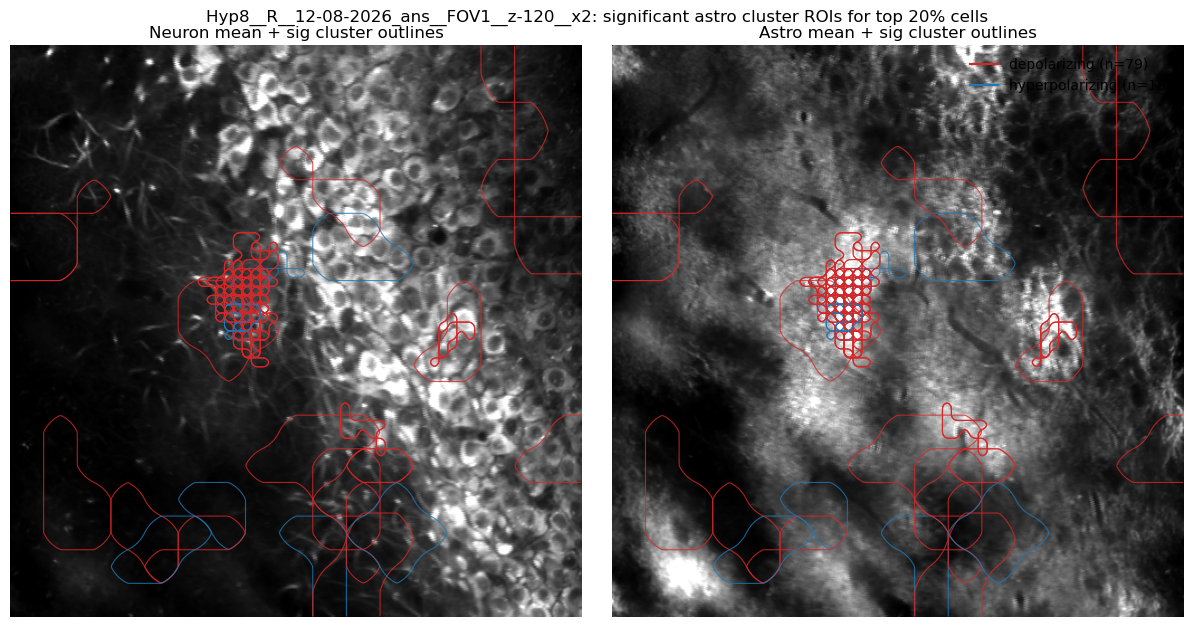

In [15]:
def resize_mask_nearest(mask, shape):
    mask = np.asarray(mask, dtype=bool)
    if mask.shape == shape:
        return mask
    if shape[0] % mask.shape[0] == 0 and shape[1] % mask.shape[1] == 0:
        y_rep = shape[0] // mask.shape[0]
        x_rep = shape[1] // mask.shape[1]
        return np.repeat(np.repeat(mask, y_rep, axis=0), x_rep, axis=1)
    return None

def _to_display_mask(mask2d, spatial_bin, display_shape):
    m = np.asarray(mask2d, dtype=np.float32)

    if int(spatial_bin) > 1:
        h = int(m.shape[0] * int(spatial_bin))
        w = int(m.shape[1] * int(spatial_bin))
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_LINEAR)

    if m.shape != tuple(display_shape):
        m = cv2.resize(m, (int(display_shape[1]), int(display_shape[0])), interpolation=cv2.INTER_LINEAR)

    m = cv2.GaussianBlur(m, (5, 5), 1.0)
    return m
if single_experiment_ready:
    sig_cluster_rows = exp_sig_clusters[exp_sig_clusters["cell_id"].isin(top_cluster_cells)].copy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
    lo_n, hi_n = np.nanpercentile(ctx.neuron_mean_img, [1, 99])
    lo_a, hi_a = np.nanpercentile(ctx.astro_mean_img, [1, 99])
    axes[0].imshow(ctx.neuron_mean_img, cmap="gray", vmin=lo_n, vmax=hi_n)
    axes[1].imshow(ctx.astro_mean_img, cmap="gray", vmin=lo_a, vmax=hi_a)
    n_dep = n_hyper = n_skipped = 0
    for _, row in sig_cluster_rows.iterrows():
        mask = cluster_mask_from_row(row)
        if mask is None:
            n_skipped += 1
            continue
        display_mask = _to_display_mask(mask, spatial_bin=1, display_shape=ctx.image_shape)
        if display_mask is None or not np.any(display_mask > 0):
            n_skipped += 1
            continue
        sign = str(row["sign"]).strip().lower()
        color = "tab:red" if sign == "positive" else "tab:blue" if sign == "negative" else "0.5"
        for ax in axes:
            ax.contour(display_mask, levels=[0.5], colors=[color], linewidths=0.8, alpha=0.8)
        if sign == "positive":
            n_dep += 1
        elif sign == "negative":
            n_hyper += 1
    axes[0].set_title("Neuron mean + sig cluster outlines")
    axes[1].set_title("Astro mean + sig cluster outlines")
    for ax in axes:
        ax.set_axis_off()
    axes[1].plot([], [], color="tab:red", label=f"depolarizing (n={n_dep})")
    axes[1].plot([], [], color="tab:blue", label=f"hyperpolarizing (n={n_hyper})")
    if n_skipped:
        axes[1].plot([], [], color="0.5", label=f"skipped shape-local masks (n={n_skipped})")
    axes[1].legend(frameon=False, loc="upper right")
    fig.suptitle(f"{ctx.canonical_id}: significant astro cluster ROIs for top {int(top_fraction * 100)}% cells", y=1.02)
    plt.show()


## Astro ROI Mean Traces and Cumulative Peak Response


Loading data...
Movie shape: (9000, 512, 512), dtype: float32


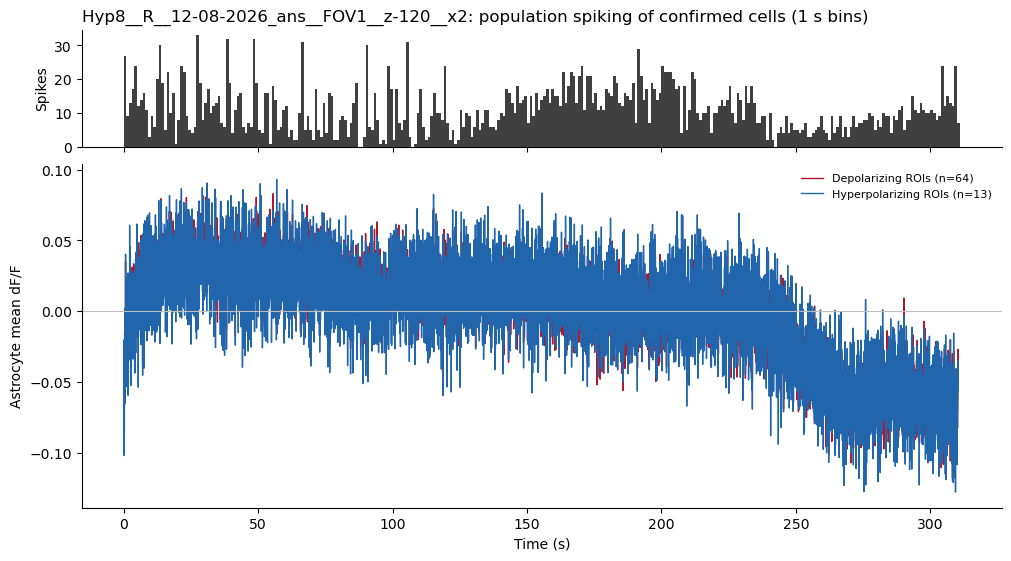

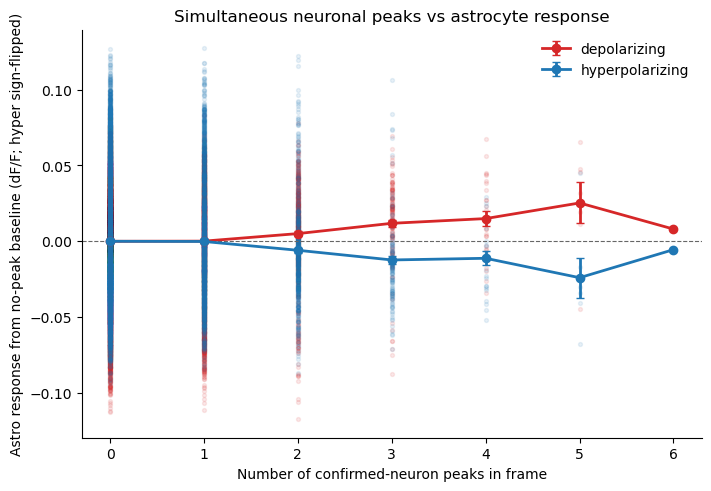

,polarity,n_peaks_in_frame,mean_voltage_magnitude,sem_voltage_magnitude,n_frames
0,depolarizing,0,0.000000e+00,0.000443,6425
1,depolarizing,1,1.007086e-04,0.000813,1908
2,depolarizing,2,5.069101e-03,0.001430,507
3,depolarizing,3,1.185535e-02,0.002490,126
4,depolarizing,4,1.498044e-02,0.005197,26
5,depolarizing,5,2.527928e-02,0.013515,7
6,depolarizing,6,8.043930e-03,NaN,1
7,hyperpolarizing,0,1.187454e-09,0.000471,6425
8,hyperpolarizing,1,-1.270716e-04,0.000852,1908
9,hyperpolarizing,2,-5.934140e-03,0.001543,507


In [16]:
if single_experiment_ready:
    astro_movie = read_astro_movie(str(ctx.paths.astro_movie_path), as_memmap=True)
    sig_cluster_rows = exp_sig_clusters[exp_sig_clusters["cell_id"].isin(top_cluster_cells)].copy()
    roi_masks = []
    roi_meta = []
    for _, row in sig_cluster_rows.iterrows():
        mask = cluster_mask_from_row(row)
        if mask is None:
            continue
        display_mask = resize_mask_nearest(mask, astro_movie.shape[1:])
        if display_mask is None or not display_mask.any():
            continue
        roi_masks.append(display_mask)
        roi_meta.append({"cell_id": int(row["cell_id"]), "cluster_id": int(row["cluster_id"]), "sign": str(row["sign"]).lower()})
    if not roi_masks:
        print("No full-frame significant-cluster masks available for astro ROI trace analysis.")
    else:
        roi_masks = np.asarray(roi_masks, dtype=bool)
        roi_meta_df = pd.DataFrame(roi_meta)
        n_frames = int(astro_movie.shape[0])
        roi_raw_traces = np.empty((roi_masks.shape[0], n_frames), dtype=np.float32)
        chunk_size = 256
        for start in range(0, n_frames, chunk_size):
            stop = min(start + chunk_size, n_frames)
            chunk = np.asarray(astro_movie[start:stop], dtype=np.float32)
            for roi_idx, mask in enumerate(roi_masks):
                roi_raw_traces[roi_idx, start:stop] = chunk[:, mask].mean(axis=1)
        f0 = np.nanpercentile(roi_raw_traces, 10, axis=1, keepdims=True)
        roi_traces = ((roi_raw_traces - f0) / (np.abs(f0) + 1e-6)).astype(np.float32)
        signs = roi_meta_df["sign"].to_numpy()
        dep_traces = roi_traces[signs == "positive"]
        hyper_traces = roi_traces[signs == "negative"]
        time_s = np.arange(n_frames) / ctx.fps
        dep_mean_trace = np.nanmean(dep_traces, axis=0) if dep_traces.size else np.full(n_frames, np.nan)
        hyper_mean_trace = np.nanmean(hyper_traces, axis=0) if hyper_traces.size else np.full(n_frames, np.nan)

        peak_counts = np.zeros(n_frames, dtype=int)
        for row in exp_peaks.itertuples():
            peaks = np.asarray(row.all_peaks, dtype=np.int32)
            peaks = peaks[(peaks >= 0) & (peaks < n_frames)]
            peak_counts[peaks] += 1
        hist_bin_seconds = 1.0
        hist_bin_frames = max(1, int(round(hist_bin_seconds * ctx.fps)))
        hist_edges = np.arange(0, n_frames + hist_bin_frames, hist_bin_frames)
        spike_hist_counts = np.histogram(np.repeat(np.arange(n_frames), peak_counts), bins=hist_edges)[0]

        fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), gridspec_kw={"height_ratios": [0.75, 2.2]}, sharex=True, constrained_layout=True)
        axes[0].bar(hist_edges[:-1] / ctx.fps, spike_hist_counts, width=np.diff(hist_edges) / ctx.fps, align="edge", color="0.25", linewidth=0)
        axes[0].set_ylabel("Spikes")
        axes[0].set_title(f"{ctx.canonical_id}: population spiking of confirmed cells ({hist_bin_seconds:g} s bins)", loc="left")
        dep_plot = dep_mean_trace - np.nanmean(dep_mean_trace)
        hyper_plot = hyper_mean_trace - np.nanmean(hyper_mean_trace)
        axes[1].plot(time_s, dep_plot, color="#b2182b", linewidth=1.0, label=f"Depolarizing ROIs (n={dep_traces.shape[0]})")
        axes[1].plot(time_s, hyper_plot, color="#2166ac", linewidth=1.0, label=f"Hyperpolarizing ROIs (n={hyper_traces.shape[0]})")
        axes[1].axhline(0, color="0.75", linewidth=0.8)
        axes[1].set_ylabel("Astrocyte mean dF/F")
        axes[1].set_xlabel("Time (s)")
        axes[1].legend(frameon=False, fontsize=8)
        for ax in axes:
            ax.spines[["top", "right"]].set_visible(False)
        plt.show()

        zero_peak_frames = peak_counts == 0
        if zero_peak_frames.any():
            dep_baseline = np.nanmean(dep_mean_trace[zero_peak_frames])
            hyper_baseline = np.nanmean(hyper_mean_trace[zero_peak_frames])
            dep_voltage_magnitude = dep_mean_trace - dep_baseline
            hyper_voltage_magnitude = -(hyper_mean_trace - hyper_baseline)
            max_peak_count = int(peak_counts.max())
            rows = []
            for polarity, values in [("depolarizing", dep_voltage_magnitude), ("hyperpolarizing", hyper_voltage_magnitude)]:
                for n_peaks in range(max_peak_count + 1):
                    vals = values[peak_counts == n_peaks]
                    vals = vals[np.isfinite(vals)]
                    if vals.size:
                        rows.append({"polarity": polarity, "n_peaks_in_frame": n_peaks, "mean_voltage_magnitude": float(np.nanmean(vals)), "sem_voltage_magnitude": float(pd.Series(vals).sem()), "n_frames": int(vals.size)})
            peak_response_df = pd.DataFrame(rows)
            fig, ax = plt.subplots(figsize=(7, 4.8), constrained_layout=True)
            colors = {"depolarizing": "tab:red", "hyperpolarizing": "tab:blue"}
            for polarity, values in [("depolarizing", dep_voltage_magnitude), ("hyperpolarizing", hyper_voltage_magnitude)]:
                ax.scatter(peak_counts, values, s=8, alpha=0.10, color=colors[polarity])
                g = peak_response_df[peak_response_df["polarity"].eq(polarity)]
                ax.errorbar(g["n_peaks_in_frame"], g["mean_voltage_magnitude"], yerr=g["sem_voltage_magnitude"].fillna(0), color=colors[polarity], marker="o", linewidth=2, capsize=3, label=polarity)
            ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)
            ax.set_xlabel("Number of confirmed-neuron peaks in frame")
            ax.set_ylabel("Astro response from no-peak baseline (dF/F; hyper sign-flipped)")
            ax.set_title("Simultaneous neuronal peaks vs astrocyte response")
            ax.legend(frameon=False)
            ax.spines[["top", "right"]].set_visible(False)
            plt.show()
            display(peak_response_df)
        else:
            print("No zero-peak frames found; cumulative peak response skipped.")
